<a href="https://colab.research.google.com/github/Varshan0128/Hired-AI-Main/blob/main/215crpto-currency%20price%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy matplotlib scikit-learn tensorflow

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from google.colab import files

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


In [2]:
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("No CSV file uploaded. Please upload the Bitcoin historical-price CSV.")

# Prefer a filename containing Bitcoin; otherwise use the first uploaded CSV.
bitcoin_files = [name for name in csv_files if "bitcoin" in name.lower()]
csv_path = bitcoin_files[0] if bitcoin_files else csv_files[0]

df = pd.read_csv(csv_path)
print("Loaded:", csv_path)
print("Original shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())


Saving coin_Aave.csv to coin_Aave.csv
Loaded: coin_Aave.csv
Original shape: (275, 10)


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Aave,AAVE,2020-10-05 23:59:59,55.112358,49.787900,52.675035,53.219243,0.000000e+00,8.912813e+07
1,2,Aave,AAVE,2020-10-06 23:59:59,53.402270,40.734578,53.291969,42.401599,5.830915e+05,7.101144e+07
2,3,Aave,AAVE,2020-10-07 23:59:59,42.408314,35.970690,42.399947,40.083976,6.828342e+05,6.713004e+07
3,4,Aave,AAVE,2020-10-08 23:59:59,44.902511,36.696057,39.885262,43.764463,1.658817e+06,2.202651e+08
4,5,Aave,AAVE,2020-10-09 23:59:59,47.569533,43.291776,43.764463,46.817744,8.155377e+05,2.356322e+08


Columns: ['SNo', 'Name', 'Symbol', 'Date', 'High', 'Low', 'Open', 'Close', 'Volume', 'Marketcap']


In [3]:
# Standardize column names and support common dataset variants.
df.columns = [str(c).strip().lower().replace(" ", "").replace("_", "") for c in df.columns]

# Map dataset variants to canonical names.
rename_map = {
    "date": "Date",
    "datetime": "Date",
    "timestamp": "Date",
    "open": "Open",
    "high": "High",
    "low": "Low",
    "close": "Close",
    "volume": "Volume",
    "marketcap": "Marketcap",
    "marketcapitalization": "Marketcap",
}
df = df.rename(columns={c: rename_map[c] for c in df.columns if c in rename_map})

if "Date" not in df.columns or "Close" not in df.columns:
    raise ValueError(
        "Could not identify Date and Close columns. "
        f"Columns found: {df.columns.tolist()}"
    )

df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True).dt.tz_localize(None)

# Convert available numerical columns; ignore non-numeric metadata.
candidate_features = ["Open", "High", "Low", "Close", "Volume", "Marketcap"]
feature_cols = [c for c in candidate_features if c in df.columns]
if "Close" not in feature_cols:
    raise ValueError("The CSV must contain a Close column.")

for col in feature_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["Date", "Close"]).sort_values("Date")
df = df.drop_duplicates(subset=["Date"], keep="last").reset_index(drop=True)

# Interpolate gaps in available numerical fields, then fill edge gaps.
df[feature_cols] = df[feature_cols].interpolate(method="linear", limit_direction="both")
df[feature_cols] = df[feature_cols].ffill().bfill()
df = df.dropna(subset=feature_cols).reset_index(drop=True)

# Keep a manageable, consecutive daily subset as requested.
df = df.tail(2000).reset_index(drop=True)

if len(df) < 30:
    raise ValueError(f"Only {len(df)} usable rows found; please upload a larger historical dataset.")

print("Rows used:", len(df))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Features:", feature_cols)
display(df[["Date"] + feature_cols].head())
display(df[["Date"] + feature_cols].tail())


Rows used: 275
Date range: 2020-10-05 to 2021-07-06
Features: ['Open', 'High', 'Low', 'Close', 'Volume', 'Marketcap']


,Date,Open,High,Low,Close,Volume,Marketcap
0,2020-10-05 23:59:59,52.675035,55.112358,49.787900,53.219243,0.000000e+00,8.912813e+07
1,2020-10-06 23:59:59,53.291969,53.402270,40.734578,42.401599,5.830915e+05,7.101144e+07
2,2020-10-07 23:59:59,42.399947,42.408314,35.970690,40.083976,6.828342e+05,6.713004e+07
3,2020-10-08 23:59:59,39.885262,44.902511,36.696057,43.764463,1.658817e+06,2.202651e+08
4,2020-10-09 23:59:59,43.764463,47.569533,43.291776,46.817744,8.155377e+05,2.356322e+08


,Date,Open,High,Low,Close,Volume,Marketcap
270,2021-07-02 23:59:59,230.814119,234.483957,215.951539,233.948437,2.566395e+08,3.001542e+09
271,2021-07-03 23:59:59,234.208478,265.107342,228.485206,259.655225,3.853778e+08,3.331546e+09
272,2021-07-04 23:59:59,259.399426,289.001124,248.285491,277.038792,4.275719e+08,3.555054e+09
273,2021-07-05 23:59:59,277.110533,317.387234,263.433881,307.829079,7.931409e+08,3.950269e+09
274,2021-07-06 23:59:59,307.997525,346.714780,307.997525,316.898507,9.887055e+08,4.066776e+09


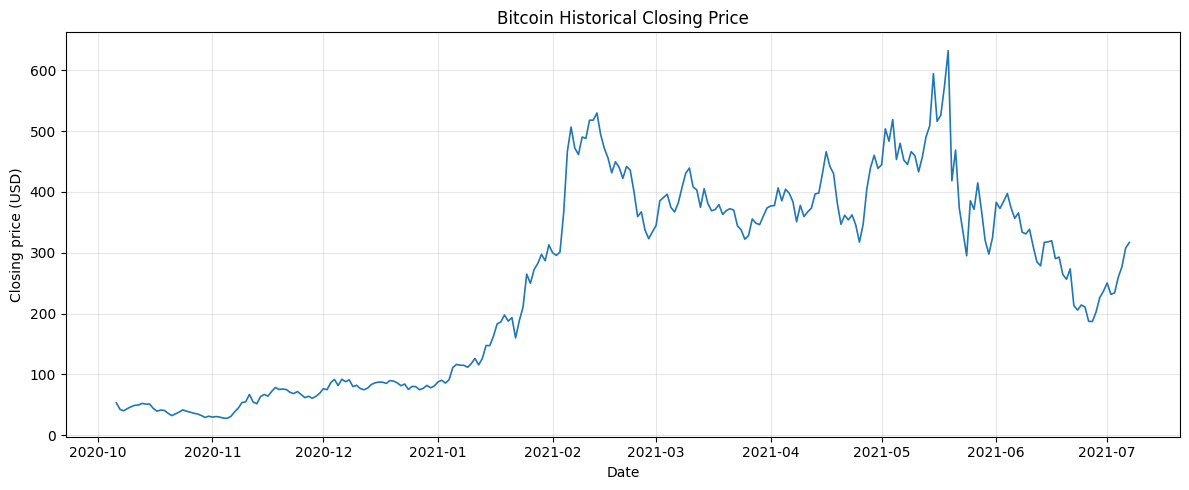

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"], linewidth=1.2)
plt.title("Bitcoin Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing price (USD)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [5]:
WINDOW_SIZE = 7
TRAIN_FRACTION = 0.80

split_idx = int(len(df) * TRAIN_FRACTION)
if split_idx <= WINDOW_SIZE or split_idx >= len(df):
    raise ValueError("Not enough data for the selected chronological split.")

# Fit feature scaler only on training rows.
feature_scaler = MinMaxScaler()
feature_scaler.fit(df.loc[:split_idx - 1, feature_cols])

scaled_features = feature_scaler.transform(df[feature_cols])

# Separate target scaler so predictions can be converted back to USD.
target_scaler = MinMaxScaler()
target_scaler.fit(df.loc[:split_idx - 1, ["Close"]])
scaled_close = target_scaler.transform(df[["Close"]]).ravel()

X_all, y_all, target_indices = [], [], []
for target_i in range(WINDOW_SIZE, len(df)):
    X_all.append(scaled_features[target_i - WINDOW_SIZE:target_i, :])
    y_all.append(scaled_close[target_i])
    target_indices.append(target_i)

X_all = np.asarray(X_all, dtype=np.float32)
y_all = np.asarray(y_all, dtype=np.float32)
target_indices = np.asarray(target_indices)

# A sample belongs to train/test according to the date of its target.
train_mask = target_indices < split_idx
test_mask = target_indices >= split_idx

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
test_target_indices = target_indices[test_mask]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)
print("Train target dates:", df.loc[target_indices[train_mask][0], "Date"].date(),
      "to", df.loc[target_indices[train_mask][-1], "Date"].date())
print("Test target dates:", df.loc[test_target_indices[0], "Date"].date(),
      "to", df.loc[test_target_indices[-1], "Date"].date())


X_train shape: (213, 7, 6)
y_train shape: (213,)
X_test shape:  (55, 7, 6)
y_test shape:  (55,)
Train target dates: 2020-10-12 to 2021-05-12
Test target dates: 2021-05-13 to 2021-07-06


In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 64)          │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,137 (121.63 KB)

 Trainable params: 31,137 (121.63 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 124ms/step - loss: 0.1406 - mean_absolute_error: 0.2821 - val_loss: 0.3144 - val_mean_absolute_error: 0.5522
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0645 - mean_absolute_error: 0.1790 - val_loss: 0.1033 - val_mean_absolute_error: 0.3070
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0090 - mean_absolute_error: 0.0755 - val_loss: 0.0111 - val_mean_absolute_error: 0.0869
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0271 - mean_absolute_error: 0.1529 - val_loss: 0.0150 - val_mean_absolute_error: 0.0986
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0105 - mean_absolute_error: 0.0900 - val_loss: 0.0228 - val_mean_absolute_error: 0.1284
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0134 - mean_absolute_error: 0.0922 - val_loss: 0.0302 - val_mean_absolute_error: 0.1485
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0077 - mean_absolute_error: 0.0657 - val_loss: 0.01

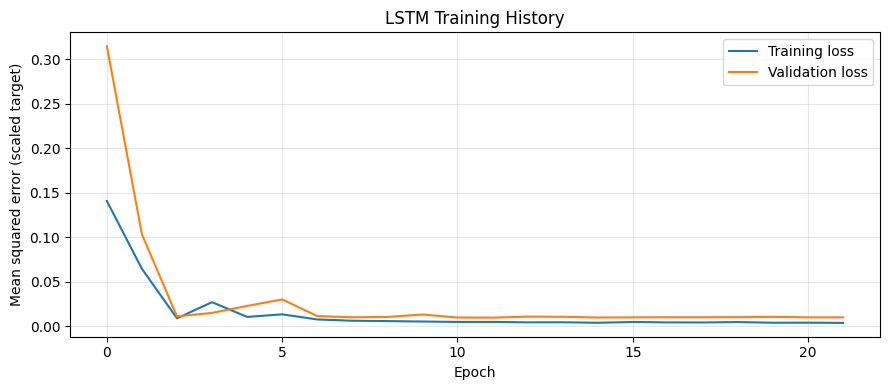

In [8]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (scaled target)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [9]:
y_pred_scaled = model.predict(X_test, verbose=0)

y_pred_usd = target_scaler.inverse_transform(y_pred_scaled).ravel()
y_test_usd = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

mae = mean_absolute_error(y_test_usd, y_pred_usd)
rmse = np.sqrt(mean_squared_error(y_test_usd, y_pred_usd))

print(f"Test MAE : ${mae:,.2f}")
print(f"Test RMSE: ${rmse:,.2f}")

results = pd.DataFrame({
    "Date": df.loc[test_target_indices, "Date"].values,
    "Actual_Close_USD": y_test_usd,
    "Predicted_Close_USD": y_pred_usd,
    "Absolute_Error_USD": np.abs(y_test_usd - y_pred_usd)
})
display(results.head(10))


Test MAE : $57.62
Test RMSE: $72.21


,Date,Actual_Close_USD,Predicted_Close_USD,Absolute_Error_USD
0,2021-05-13 23:59:59,508.622772,454.754547,53.868225
1,2021-05-14 23:59:59,594.556885,461.335815,133.221069
2,2021-05-15 23:59:59,516.169373,473.979553,42.189819
3,2021-05-16 23:59:59,526.214722,485.536591,40.678131
4,2021-05-17 23:59:59,574.259399,496.923798,77.335602
5,2021-05-18 23:59:59,632.266418,510.005341,122.261078
6,2021-05-19 23:59:59,418.369324,524.645874,106.276550
7,2021-05-20 23:59:59,468.812683,523.244080,54.431396
8,2021-05-21 23:59:59,373.418518,518.397766,144.979248
9,2021-05-22 23:59:59,334.480682,507.778381,173.297699


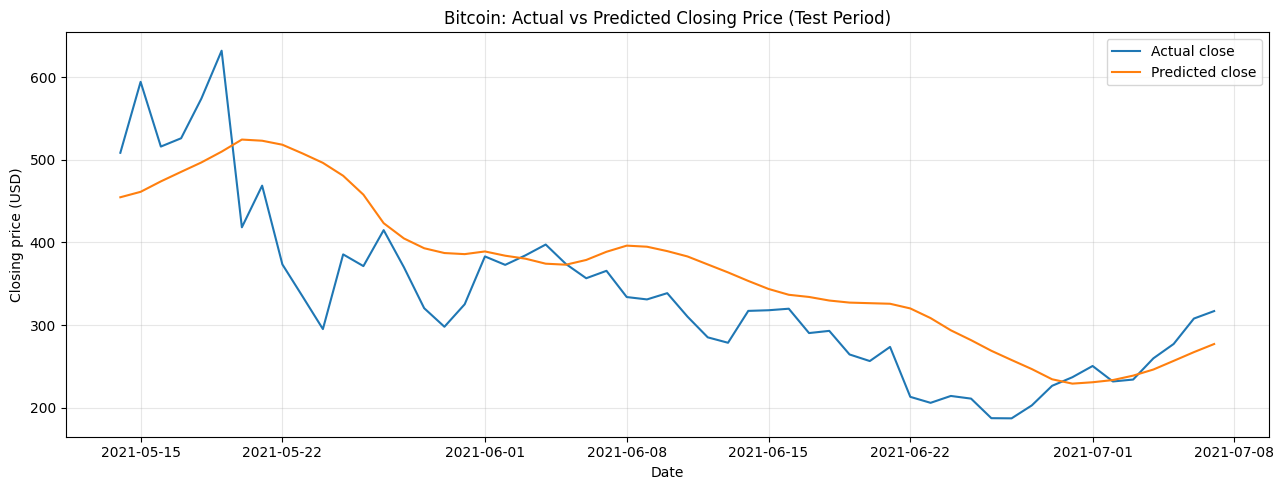

In [10]:
plt.figure(figsize=(13, 5))
plt.plot(results["Date"], results["Actual_Close_USD"], label="Actual close", linewidth=1.5)
plt.plot(results["Date"], results["Predicted_Close_USD"], label="Predicted close", linewidth=1.5)
plt.title("Bitcoin: Actual vs Predicted Closing Price (Test Period)")
plt.xlabel("Date")
plt.ylabel("Closing price (USD)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


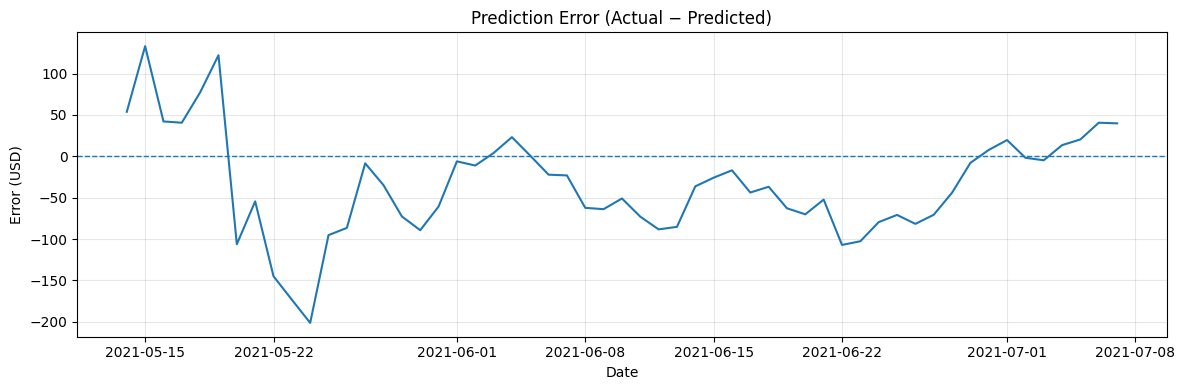

Sample predictions:


,Date,Actual_Close_USD,Predicted_Close_USD,Absolute_Error_USD
45,2021-06-27 23:59:59,202.679993,246.639999,43.959999
46,2021-06-28 23:59:59,226.369995,234.279999,7.910000
47,2021-06-29 23:59:59,236.770004,229.020004,7.750000
48,2021-06-30 23:59:59,250.389999,230.690002,19.700001
49,2021-07-01 23:59:59,231.630005,233.339996,1.710000
50,2021-07-02 23:59:59,233.949997,238.699997,4.750000
51,2021-07-03 23:59:59,259.660004,246.100006,13.550000
52,2021-07-04 23:59:59,277.040009,256.579987,20.459999
53,2021-07-05 23:59:59,307.829987,267.160004,40.669998
54,2021-07-06 23:59:59,316.899994,277.000000,39.900002


In [11]:
plt.figure(figsize=(12, 4))
plt.plot(results["Date"], results["Actual_Close_USD"] - results["Predicted_Close_USD"])
plt.axhline(0, linestyle="--", linewidth=1)
plt.title("Prediction Error (Actual − Predicted)")
plt.xlabel("Date")
plt.ylabel("Error (USD)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Sample predictions:")
display(results.tail(10).round(2))

In [12]:
last_7_days = scaled_features[-WINDOW_SIZE:, :].reshape(1, WINDOW_SIZE, len(feature_cols))
next_close_scaled = model.predict(last_7_days, verbose=0)
next_close_usd = target_scaler.inverse_transform(next_close_scaled)[0, 0]

last_date = df["Date"].iloc[-1]
next_date = last_date + pd.Timedelta(days=1)

print("Last observed date:", last_date.date())
print("Forecast date:     ", next_date.date())
print(f"Predicted next-day closing price: ${next_close_usd:,.2f}")


Last observed date: 2021-07-06
Forecast date:      2021-07-07
Predicted next-day closing price: $288.04


In [13]:
model.save("bitcoin_lstm_model.keras")
results.to_csv("bitcoin_test_predictions.csv", index=False)

print("Saved: bitcoin_lstm_model.keras")
print("Saved: bitcoin_test_predictions.csv")

files.download("bitcoin_test_predictions.csv")
files.download("bitcoin_lstm_model.keras")


Saved: bitcoin_lstm_model.keras
Saved: bitcoin_test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>